# NYC weather EDA and daily features — 2016–2017

**Source:** `data/NYC_Weather_2016_2022.csv`  
**Goal:** audit hourly weather data, understand seasonal patterns and extremes, and identify useful inputs for Citi Bike demand forecasting.

The source file is filtered to **2016–2017 before all analysis**. All tables, plots, and daily features use only these two years. The source is unchanged; a daily CSV is exported for joining to other daily features.

**Important metadata limitation:** timestamps have no timezone offset, and the file does not document its source, location, or precipitation accumulation convention. Hour-of-day patterns refer to the supplied clock, not verified NYC local time. Confirm these details before joining to trips or making operational forecasts.

## Contents
1. Load and field definitions
2. Data quality, hourly continuity, and missingness
3. Distributions and seasonal/diurnal patterns
4. Precipitation, extremes, and feature relationships
5. Daily aggregation, validation, and CSV export

**Dependencies:** Python, pandas, NumPy, Matplotlib, seaborn, and Jupyter. All analysis is local; no external data is downloaded.

In [1]:
%matplotlib inline
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.max_columns", 25)
pd.set_option("display.precision", 3)

# Work when launched from the repository root or notebooks directory.
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "data" / "NYC_Weather_2016_2022.csv").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Run inside the repository containing data/NYC_Weather_2016_2022.csv")
DATA_PATH = ROOT / "data" / "NYC_Weather_2016_2022.csv"
raw = pd.read_csv(DATA_PATH)
raw["time"] = pd.to_datetime(raw["time"], errors="raise")
# Restrict the data before any quality checks, statistics, plots, or aggregation.
ANALYSIS_YEARS = (2016, 2017)
raw = raw.loc[raw["time"].dt.year.isin(ANALYSIS_YEARS)].copy()
assert set(raw["time"].dt.year.unique()) == set(ANALYSIS_YEARS)
rename = {
    "temperature_2m (°C)": "temperature_c",
    "precipitation (mm)": "precipitation_mm",
    "rain (mm)": "rain_mm",
    "cloudcover (%)": "cloud_pct",
    "cloudcover_low (%)": "cloud_low_pct",
    "cloudcover_mid (%)": "cloud_mid_pct",
    "cloudcover_high (%)": "cloud_high_pct",
    "windspeed_10m (km/h)": "wind_speed_kmh",
    "winddirection_10m (°)": "wind_direction_deg",
}
weather = raw.rename(columns=rename).copy()
weather["time"] = pd.to_datetime(weather["time"], errors="raise")
features = list(rename.values())
print(f"Source: {DATA_PATH.relative_to(ROOT)}")
print(f"Shape: {len(weather):,} rows × {len(weather.columns)} columns")
print(f"Timestamp range: {weather.time.min()} to {weather.time.max()}")
display(weather.head())
display(pd.DataFrame({"source_field": list(rename), "analysis_field": features,
                      "dtype": [str(weather[c].dtype) for c in features]}))

Source: data/NYC_Weather_2016_2022.csv
Shape: 17,544 rows × 10 columns
Timestamp range: 2016-01-01 00:00:00 to 2017-12-31 23:00:00


,time,temperature_c,precipitation_mm,rain_mm,cloud_pct,cloud_low_pct,cloud_mid_pct,cloud_high_pct,wind_speed_kmh,wind_direction_deg
0,2016-01-01 00:00:00,7.6,0.0,0.0,69.0,53.0,0.0,72.0,10.0,296.0
1,2016-01-01 01:00:00,7.5,0.0,0.0,20.0,4.0,0.0,56.0,9.8,287.0
2,2016-01-01 02:00:00,7.1,0.0,0.0,32.0,3.0,0.0,99.0,9.7,285.0
3,2016-01-01 03:00:00,6.6,0.0,0.0,35.0,5.0,0.0,100.0,9.2,281.0
4,2016-01-01 04:00:00,6.3,0.0,0.0,34.0,4.0,0.0,100.0,9.1,279.0


,source_field,analysis_field,dtype
0,temperature_2m (°C),temperature_c,float64
1,precipitation (mm),precipitation_mm,float64
2,rain (mm),rain_mm,float64
3,cloudcover (%),cloud_pct,float64
4,cloudcover_low (%),cloud_low_pct,float64
5,cloudcover_mid (%),cloud_mid_pct,float64
6,cloudcover_high (%),cloud_high_pct,float64
7,windspeed_10m (km/h),wind_speed_kmh,float64
8,winddirection_10m (°),wind_direction_deg,float64


## 1. Data quality

Check parsing, ordering, duplicate timestamps, missing hours, plausible physical ranges, and rain/precipitation consistency. Physical checks are broad sanity checks, not proof that every value is correct. Weather extremes are retained rather than removed as statistical outliers.

In [2]:
time = weather["time"]
expected_hours = pd.date_range("2016-01-01", "2017-12-31 23:00", freq="h")
missing_hours = expected_hours.difference(pd.DatetimeIndex(time))
quality = pd.Series({
    "rows": len(weather),
    "duplicate_rows": raw.duplicated().sum(),
    "duplicate_timestamps": time.duplicated().sum(),
    "timestamps_sorted": time.is_monotonic_increasing,
    "missing_hourly_timestamps": len(missing_hours),
    "off_hour_timestamps": (time != time.dt.floor("h")).sum(),
    "rows_all_weather_missing": weather[features].isna().all(axis=1).sum(),
    "rows_any_weather_missing": weather[features].isna().any(axis=1).sum(),
})
display(quality.to_frame("value"))
missing_summary = pd.DataFrame({
    "missing_count": weather[features].isna().sum(),
    "missing_pct": weather[features].isna().mean() * 100,
    "distinct_observed_values": weather[features].nunique(),
})
display(missing_summary)
assert not time.duplicated().any(), "Resolve duplicate timestamps before resampling."
assert len(missing_hours) == 0, "Investigate missing timestamp coverage."
w = weather.set_index("time").sort_index()

all_missing = w[features].isna().all(axis=1)
run_id = all_missing.ne(all_missing.shift()).cumsum()
missing_blocks = (w.index.to_series().loc[all_missing]
                  .groupby(run_id.loc[all_missing]).agg(["min", "max", "size"])
                  .rename(columns={"min": "start", "max": "end", "size": "hours"}))
display(missing_blocks)
print("Missing direction outside all-weather outages:")
display(w.loc[w.wind_direction_deg.isna() & ~all_missing,
              ["temperature_c", "precipitation_mm", "wind_speed_kmh", "wind_direction_deg"]])

bounds = {
    "temperature_c": (-50, 55), "precipitation_mm": (0, np.inf),
    "rain_mm": (0, np.inf), "wind_speed_kmh": (0, np.inf),
    "wind_direction_deg": (0, 360),
    **{c: (0, 100) for c in features if "cloud" in c},
}
range_checks = pd.Series({c: int((w[c].notna() & ~w[c].between(lo, hi)).sum())
                          for c, (lo, hi) in bounds.items()}, name="out_of_range_rows")
display(range_checks.to_frame())
print("Hours where rain > precipitation:", int((w.rain_mm > w.precipitation_mm + 1e-9).sum()))

,value
rows,17544
duplicate_rows,0
duplicate_timestamps,0
timestamps_sorted,True
missing_hourly_timestamps,0
off_hour_timestamps,0
rows_all_weather_missing,0
rows_any_weather_missing,0


,missing_count,missing_pct,distinct_observed_values
temperature_c,0,0.0,474
precipitation_mm,0,0.0,68
rain_mm,0,0.0,66
cloud_pct,0,0.0,101
cloud_low_pct,0,0.0,101
cloud_mid_pct,0,0.0,101
cloud_high_pct,0,0.0,101
wind_speed_kmh,0,0.0,355
wind_direction_deg,0,0.0,360


,start,end,hours


Missing direction outside all-weather outages:


,temperature_c,precipitation_mm,wind_speed_kmh,wind_direction_deg
time,,,,


,out_of_range_rows
temperature_c,0
precipitation_mm,0
rain_mm,0
wind_speed_kmh,0
wind_direction_deg,0
cloud_pct,0
cloud_low_pct,0
cloud_mid_pct,0
cloud_high_pct,0


Hours where rain > precipitation: 0


,timestamp_rows,full_calendar_hours,temperature_c,precipitation_mm,rain_mm,cloud_pct,cloud_low_pct,cloud_mid_pct,cloud_high_pct,wind_speed_kmh,wind_direction_deg,temperature_calendar_coverage_pct
time,,,,,,,,,,,,
2016,8784,8784,8784,8784,8784,8784,8784,8784,8784,8784,8784,100.0
2017,8760,8760,8760,8760,8760,8760,8760,8760,8760,8760,8760,100.0


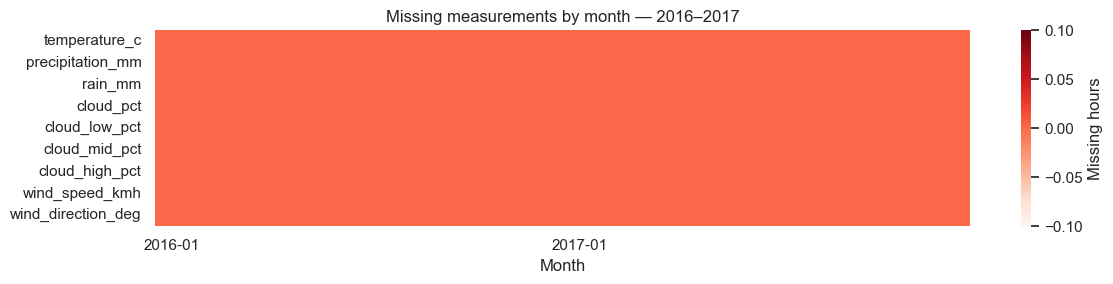

In [3]:
annual_quality = w[features].groupby(w.index.year).count()
annual_quality.insert(0, "timestamp_rows", w.groupby(w.index.year).size())
annual_quality.insert(1, "full_calendar_hours", [
    len(pd.date_range(f"{y}-01-01", f"{y+1}-01-01", freq="h", inclusive="left"))
    for y in annual_quality.index
])
annual_quality["temperature_calendar_coverage_pct"] = (
    100 * annual_quality.temperature_c / annual_quality.full_calendar_hours)
display(annual_quality)
fig, ax = plt.subplots(figsize=(12, 3))
monthly_missing = w[features].isna().resample("MS").sum()
sns.heatmap(monthly_missing.T, cmap="Reds", ax=ax, xticklabels=False,
            cbar_kws={"label": "Missing hours"})
positions = np.arange(0, len(monthly_missing), 12)
ax.set_xticks(positions + .5)
ax.set_xticklabels(monthly_missing.index[positions].strftime("%Y-%m"), rotation=0)
ax.set(title="Missing measurements by month — 2016–2017", xlabel="Month", ylabel="")
plt.tight_layout()
plt.show()

### Quality interpretation — 2016–2017

- **17,544 hourly rows**, with a sorted, unique, continuous hourly grid covering both full calendar years.
- All nine weather fields are complete in this window; no imputation is needed.
- No values fail the stated physical bounds, and rain never exceeds total precipitation.
- Daily grouping below uses the supplied timezone-naive clock. Confirm that its calendar days match your other daily features before joining; no timezone is guessed or silently converted.

## 2. Numerical distributions

Wind direction is circular: 1° and 360° are close, not opposite. It is excluded from ordinary linear summaries and correlations below. Precipitation has a large mass at zero, so examine positive amounts separately.

,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
temperature_c,17544.0,13.158,9.701,-16.8,-7.757,-2.6,5.4,13.4,21.5,27.6,30.8,34.5
precipitation_mm,17544.0,0.115,0.497,0.0,0.000,0.0,0.0,0.0,0.0,0.7,2.3,19.2
rain_mm,17544.0,0.104,0.472,0.0,0.000,0.0,0.0,0.0,0.0,0.6,2.1,19.2
cloud_pct,17544.0,44.745,38.155,0.0,0.000,0.0,7.0,33.0,87.0,100.0,100.0,100.0
cloud_low_pct,17544.0,25.069,36.949,0.0,0.000,0.0,0.0,2.0,44.0,100.0,100.0,100.0
cloud_mid_pct,17544.0,29.622,36.637,0.0,0.000,0.0,0.0,10.0,55.0,100.0,100.0,100.0
cloud_high_pct,17544.0,38.737,42.114,0.0,0.000,0.0,0.0,16.0,90.0,100.0,100.0,100.0
wind_speed_kmh,17544.0,11.380,5.818,0.4,1.600,3.6,7.2,10.4,14.6,22.4,29.2,41.3


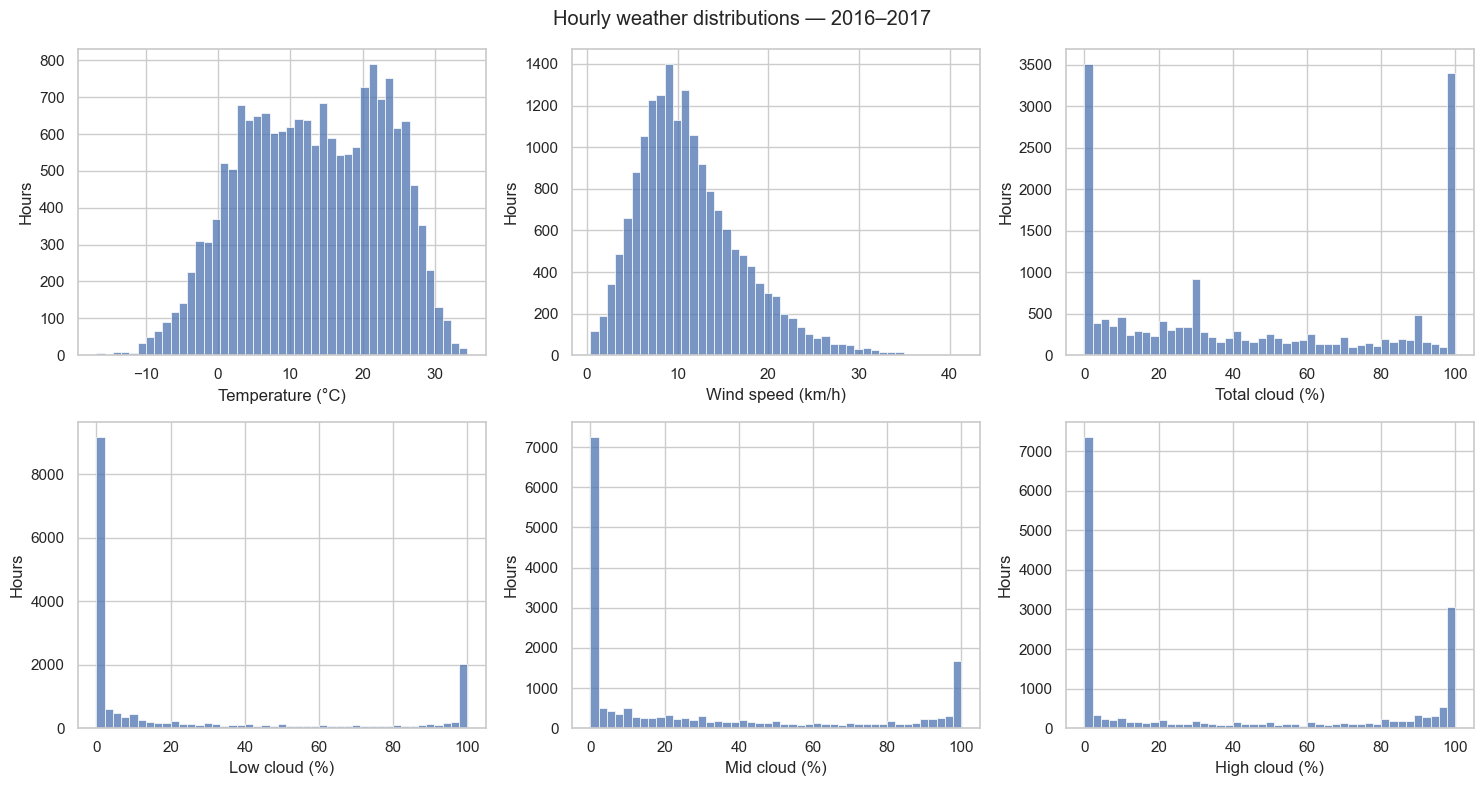

,value
observed_hours,17544.00
wet_hours,2293.00
wet_hour_pct,13.07
zero_precipitation_pct,86.93
wet_hour_median_mm,0.50
wet_hour_p95_mm,2.90
maximum_hourly_mm,19.20


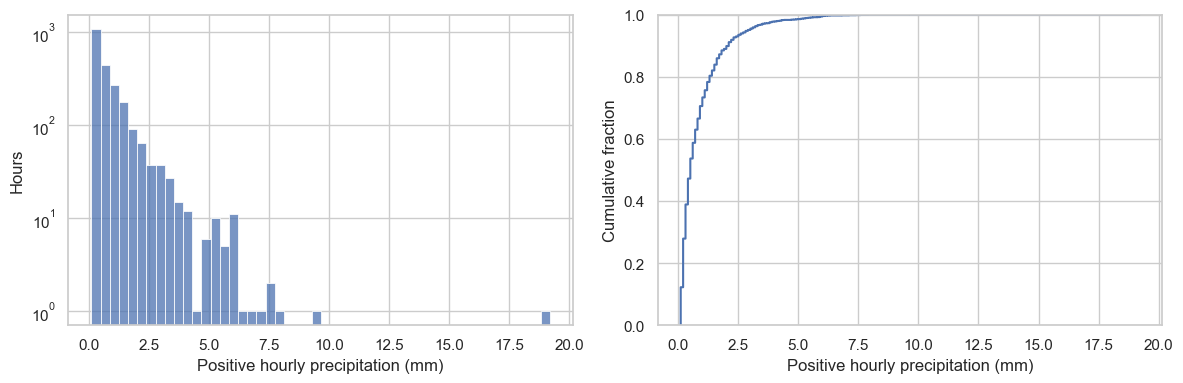

In [4]:
linear_features = [c for c in features if c != "wind_direction_deg"]
display(w[linear_features].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).T)
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
for ax, c, label in zip(axes.flat,
                       ["temperature_c", "wind_speed_kmh", "cloud_pct", "cloud_low_pct", "cloud_mid_pct", "cloud_high_pct"],
                       ["Temperature (°C)", "Wind speed (km/h)", "Total cloud (%)", "Low cloud (%)", "Mid cloud (%)", "High cloud (%)"]):
    sns.histplot(w[c].dropna(), bins=45, ax=ax)
    ax.set(xlabel=label, ylabel="Hours")
plt.suptitle("Hourly weather distributions — 2016–2017")
plt.tight_layout()
plt.show()

precip = w.precipitation_mm.dropna()
positive_precip = precip[precip > 0]
display(pd.Series({
    "observed_hours": len(precip), "wet_hours": len(positive_precip),
    "wet_hour_pct": 100 * (precip > 0).mean(),
    "zero_precipitation_pct": 100 * (precip == 0).mean(),
    "wet_hour_median_mm": positive_precip.median(),
    "wet_hour_p95_mm": positive_precip.quantile(.95),
    "maximum_hourly_mm": precip.max(),
}).to_frame("value"))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(positive_precip, bins=50, ax=axes[0])
axes[0].set(xlabel="Positive hourly precipitation (mm)", ylabel="Hours", yscale="log")
sns.ecdfplot(positive_precip, ax=axes[1])
axes[1].set(xlabel="Positive hourly precipitation (mm)", ylabel="Cumulative fraction")
plt.tight_layout()
plt.show()

## 3. Seasonality and supplied-clock hour patterns

Temperature and wind use means; hourly precipitation uses sums for daily/monthly totals. Sums assume the labeled hourly values are per-hour amounts—verify the source convention. Daily/monthly totals with any missing precipitation measurements are masked instead of silently treating missing hours as dry. Daily extrema also require full temperature coverage. Means use observed values.

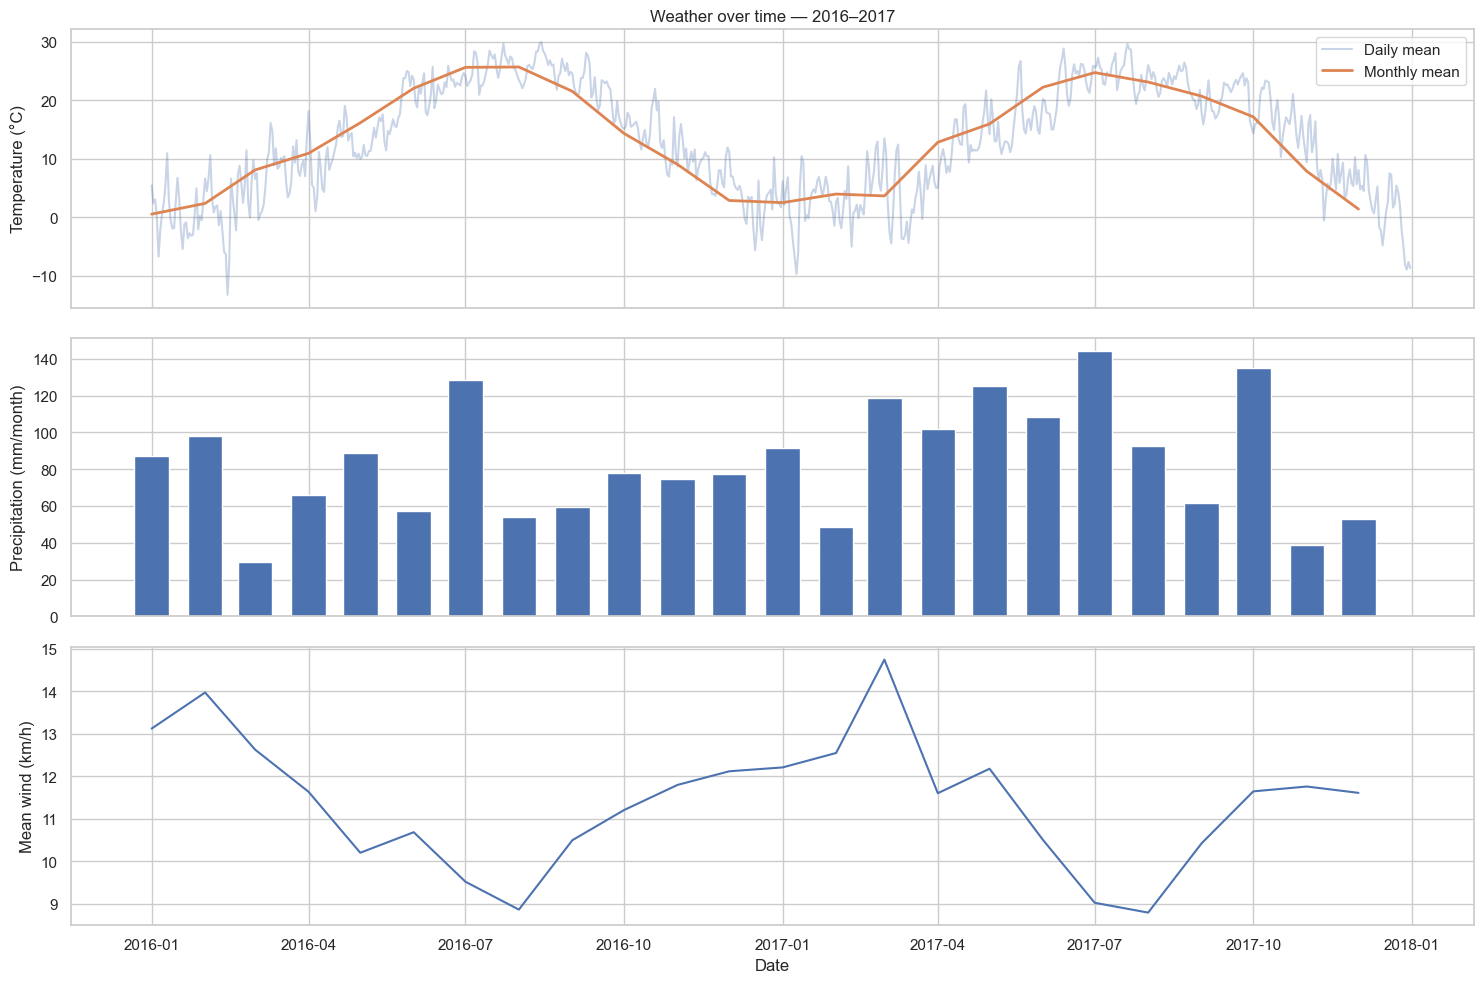

,temperature_c,wind_speed_kmh,cloud_pct,wet_hour_pct
month,,,,
1,1.490,12.667,49.124,13.306
2,3.126,13.273,43.756,12.500
3,5.844,13.686,44.749,13.508
4,11.859,11.621,47.315,13.611
5,16.040,11.191,55.554,17.406
6,22.136,10.596,38.448,12.292
7,25.176,9.275,44.070,15.860
8,24.398,8.832,39.004,12.298
9,21.107,10.462,43.788,12.431


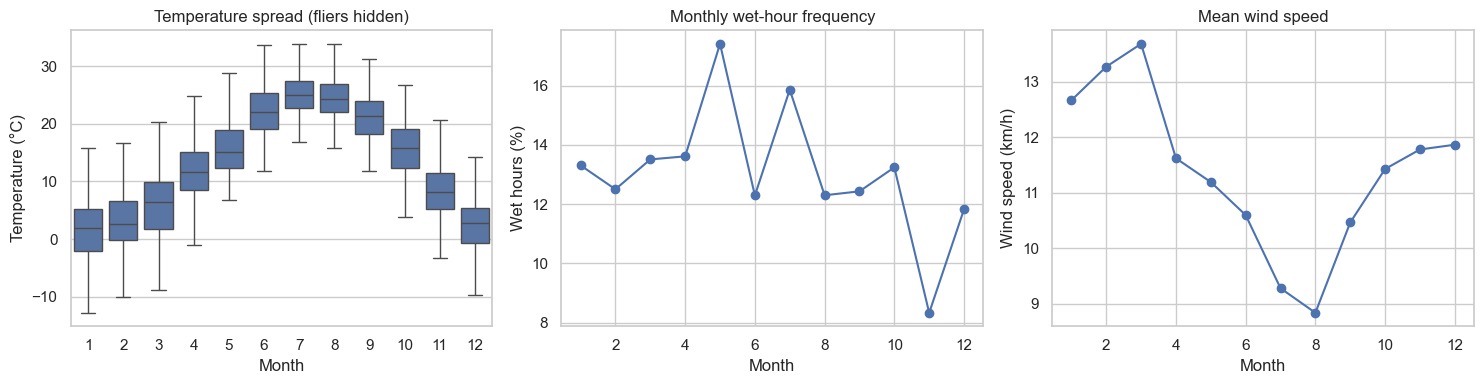

In [5]:
daily = w.resample("D").agg(
    temperature_mean_c=("temperature_c", "mean"),
    temperature_min_c=("temperature_c", "min"),
    temperature_max_c=("temperature_c", "max"),
    temperature_hours=("temperature_c", "count"),
    precipitation_mm=("precipitation_mm", lambda s: s.sum(min_count=1)),
    precipitation_hours=("precipitation_mm", "count"),
    wind_mean_kmh=("wind_speed_kmh", "mean"),
    wind_max_kmh=("wind_speed_kmh", "max"),
    cloud_mean_pct=("cloud_pct", "mean"),
)
daily.loc[daily.precipitation_hours != 24, "precipitation_mm"] = np.nan
daily.loc[daily.temperature_hours != 24, ["temperature_min_c", "temperature_max_c"]] = np.nan
monthly = w.resample("MS").agg(
    temperature_c=("temperature_c", "mean"),
    precipitation_mm=("precipitation_mm", lambda s: s.sum(min_count=1)),
    precipitation_hours=("precipitation_mm", "count"),
    wind_speed_kmh=("wind_speed_kmh", "mean"),
)
monthly["expected_hours"] = monthly.index.days_in_month * 24
monthly.loc[monthly.precipitation_hours != monthly.expected_hours, "precipitation_mm"] = np.nan

fig, axes = plt.subplots(3, 1, figsize=(15, 10), sharex=True)
axes[0].plot(daily.index, daily.temperature_mean_c, alpha=.3, label="Daily mean")
axes[0].plot(monthly.index, monthly.temperature_c, linewidth=2, label="Monthly mean")
axes[0].set(ylabel="Temperature (°C)", title="Weather over time — 2016–2017")
axes[0].legend()
axes[1].bar(monthly.index, monthly.precipitation_mm, width=20)
axes[1].set(ylabel="Precipitation (mm/month)")
axes[2].plot(monthly.index, monthly.wind_speed_kmh)
axes[2].set(ylabel="Mean wind (km/h)", xlabel="Date")
plt.tight_layout()
plt.show()

# Use complete calendar years for comparable seasonal summaries.
full_years = w.copy()  # Already restricted to 2016–2017.
monthly_climate = full_years.groupby(full_years.index.month)[
    ["temperature_c", "wind_speed_kmh", "cloud_pct"]].mean()
monthly_climate["wet_hour_pct"] = 100 * full_years.precipitation_mm.dropna().gt(0).groupby(
    full_years.precipitation_mm.dropna().index.month).mean()
monthly_climate.index.name = "month"
display(monthly_climate)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(x=full_years.index.month, y=full_years.temperature_c, showfliers=False, ax=axes[0])
axes[0].set(xlabel="Month", ylabel="Temperature (°C)", title="Temperature spread (fliers hidden)")
axes[1].plot(monthly_climate.index, monthly_climate.wet_hour_pct, marker="o")
axes[1].set(xlabel="Month", ylabel="Wet hours (%)", title="Monthly wet-hour frequency")
axes[2].plot(monthly_climate.index, monthly_climate.wind_speed_kmh, marker="o")
axes[2].set(xlabel="Month", ylabel="Wind speed (km/h)", title="Mean wind speed")
plt.tight_layout()
plt.show()

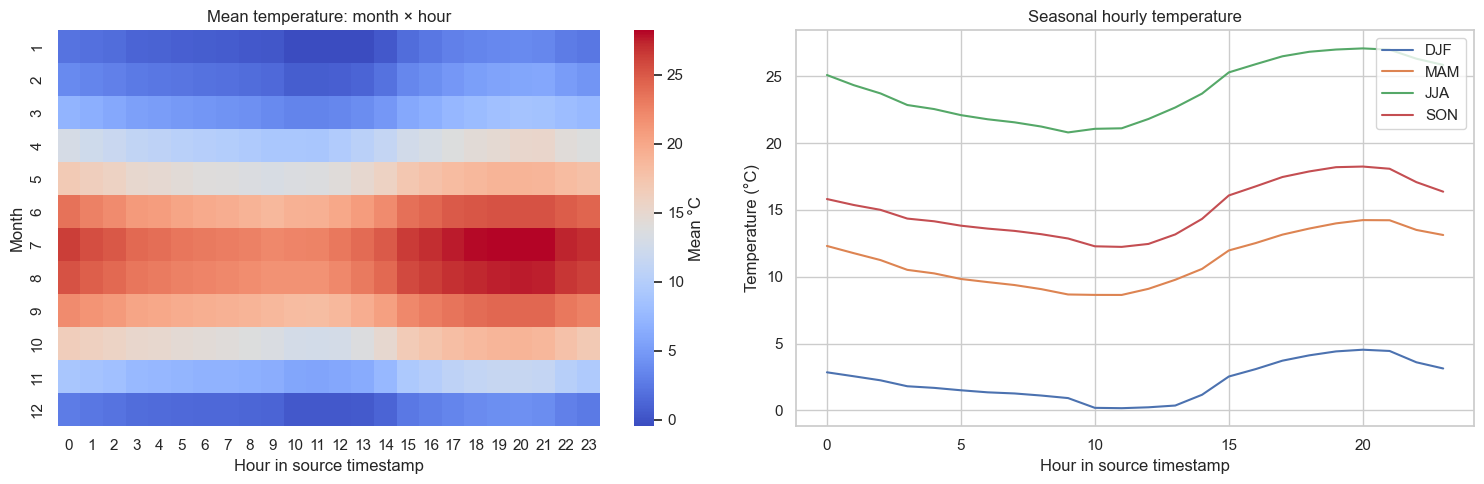

These hours must not be interpreted as NYC local time until the source timezone is confirmed.


In [6]:
hour_month = full_years.pivot_table(values="temperature_c", index=full_years.index.month,
                                  columns=full_years.index.hour, aggfunc="mean")
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.heatmap(hour_month, cmap="coolwarm", ax=axes[0], cbar_kws={"label": "Mean °C"})
axes[0].set(xlabel="Hour in source timestamp", ylabel="Month", title="Mean temperature: month × hour")
for name, months in {"DJF": [12, 1, 2], "MAM": [3, 4, 5], "JJA": [6, 7, 8], "SON": [9, 10, 11]}.items():
    part = full_years.loc[full_years.index.month.isin(months)]
    axes[1].plot(part.groupby(part.index.hour).temperature_c.mean(), label=name)
axes[1].set(xlabel="Hour in source timestamp", ylabel="Temperature (°C)", title="Seasonal hourly temperature")
axes[1].legend()
plt.tight_layout()
plt.show()
print("These hours must not be interpreted as NYC local time until the source timezone is confirmed.")

## 4. Extremes, precipitation relationships, and wind direction

The thresholds below are illustrative feature definitions, not official weather-warning criteria. Rates use nonmissing observations for each variable. A precipitation-minus-rain residual is **not** a validated snow measurement; it may include other precipitation or reflect source definitions.

,hours,observed_hours,pct
event,,,
Freezing: temperature ≤ 0°C,1673,17544,9.536
Hot: temperature ≥ 30°C,278,17544,1.585
Wet: precipitation > 0 mm,2293,17544,13.070
Precipitation ≥ 1 mm/hour,676,17544,3.853
Precipitation ≥ 5 mm/hour,35,17544,0.199
Wind ≥ 30 km/h,141,17544,0.804


Coldest hours:


,temperature_c,wind_speed_kmh
time,,
2016-02-14 12:00:00,-16.8,18.4
2016-02-14 13:00:00,-16.8,18.2
2016-02-14 11:00:00,-16.6,18.9
2016-02-14 10:00:00,-16.3,18.7
2016-02-14 14:00:00,-16.3,17.2


Hottest hours:


,temperature_c,wind_speed_kmh
time,,
2017-06-13 20:00:00,34.5,10.9
2016-08-14 20:00:00,34.3,13.0
2016-08-13 20:00:00,34.1,12.9
2016-07-23 21:00:00,33.9,18.2
2016-08-13 19:00:00,33.9,11.3


Wettest fully observed days:


,precipitation_mm,precipitation_hours,temperature_mean_c
time,,,
2017-03-14,51.2,24,-0.775
2017-07-24,46.7,24,21.396
2016-01-23,40.0,24,-2.783
2017-06-24,34.0,24,26.154
2017-01-24,32.2,24,3.521
2017-10-24,32.0,24,21.054
2017-05-05,31.8,24,13.008
2016-01-10,31.2,24,10.917
2017-10-29,29.2,24,17.317


Windiest hours:


,wind_speed_kmh,temperature_c,precipitation_mm
time,,,
2016-04-03 15:00:00,41.3,3.0,0.0
2016-04-03 13:00:00,38.0,2.3,0.0
2016-04-03 14:00:00,37.9,2.3,0.0
2016-01-23 15:00:00,37.7,-2.5,4.1
2016-04-03 12:00:00,37.7,2.1,0.0


Rain equals precipitation in 98.47% of paired hours.
Positive precipitation-minus-rain residual in 268 hours; not necessarily snow.


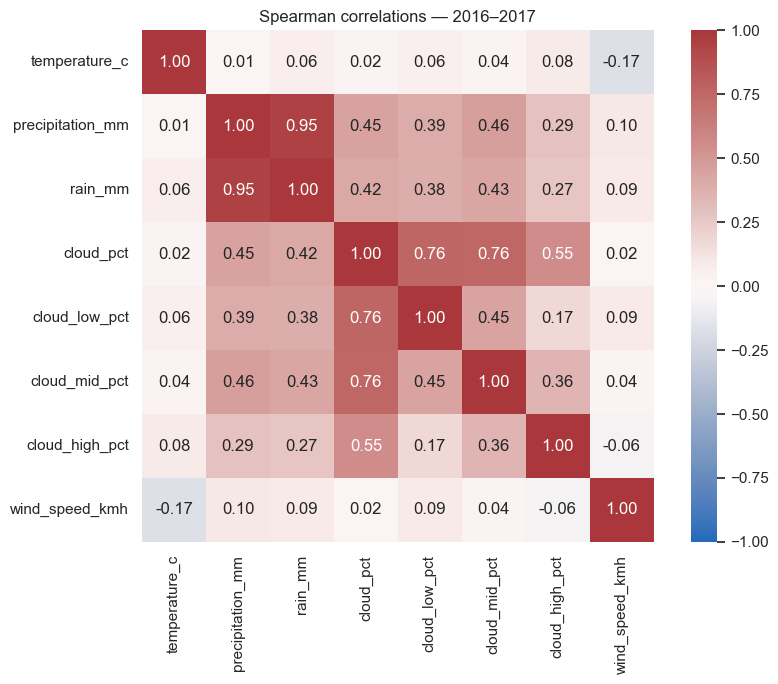

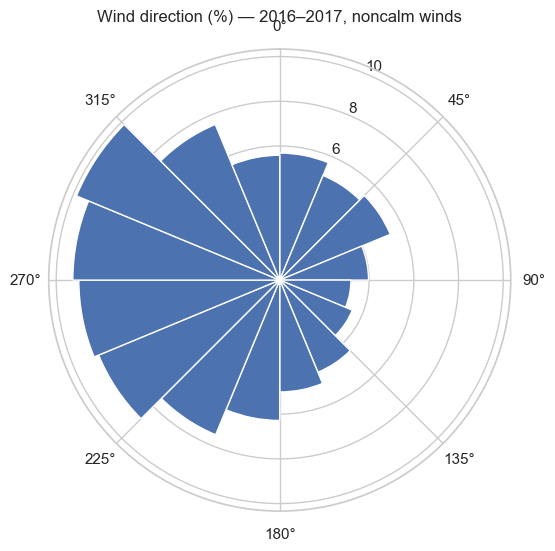

In [7]:
events = {
    "Freezing: temperature ≤ 0°C": ("temperature_c", lambda s: s <= 0),
    "Hot: temperature ≥ 30°C": ("temperature_c", lambda s: s >= 30),
    "Wet: precipitation > 0 mm": ("precipitation_mm", lambda s: s > 0),
    "Precipitation ≥ 1 mm/hour": ("precipitation_mm", lambda s: s >= 1),
    "Precipitation ≥ 5 mm/hour": ("precipitation_mm", lambda s: s >= 5),
    "Wind ≥ 30 km/h": ("wind_speed_kmh", lambda s: s >= 30),
}
event_rows = []
for name, (column, predicate) in events.items():
    observed = w[column].dropna()
    event_rows.append({"event": name, "hours": int(predicate(observed).sum()),
                       "observed_hours": len(observed), "pct": 100 * predicate(observed).mean()})
display(pd.DataFrame(event_rows).set_index("event"))
print("Coldest hours:")
display(w.nsmallest(5, "temperature_c")[["temperature_c", "wind_speed_kmh"]])
print("Hottest hours:")
display(w.nlargest(5, "temperature_c")[["temperature_c", "wind_speed_kmh"]])
print("Wettest fully observed days:")
display(daily.nlargest(10, "precipitation_mm")[["precipitation_mm", "precipitation_hours", "temperature_mean_c"]])
print("Windiest hours:")
display(w.nlargest(5, "wind_speed_kmh")[["wind_speed_kmh", "temperature_c", "precipitation_mm"]])

paired = w[["precipitation_mm", "rain_mm"]].dropna()
residual = paired.precipitation_mm - paired.rain_mm
print(f"Rain equals precipitation in {100 * np.isclose(paired.rain_mm, paired.precipitation_mm).mean():.2f}% of paired hours.")
print(f"Positive precipitation-minus-rain residual in {(residual > 1e-9).sum():,} hours; not necessarily snow.")

fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(w[linear_features].corr(method="spearman"), annot=True, fmt=".2f", vmin=-1, vmax=1,
            cmap="vlag", square=True, ax=ax)
ax.set_title("Spearman correlations — 2016–2017")
plt.tight_layout()
plt.show()

# Exclude calm winds and encode direction circularly for visualization.
wind = w.loc[w.wind_speed_kmh.gt(0) & w.wind_direction_deg.notna()]
angles = np.deg2rad(wind.wind_direction_deg % 360)
counts, edges = np.histogram(angles, bins=np.linspace(0, 2 * np.pi, 17))
fig, ax = plt.subplots(figsize=(6, 6), subplot_kw={"projection": "polar"})
ax.bar((edges[:-1] + edges[1:]) / 2, counts / counts.sum() * 100,
       width=np.diff(edges), edgecolor="white")
ax.set_theta_zero_location("N")
ax.set_theta_direction(-1)
ax.set_title("Wind direction (%) — 2016–2017, noncalm winds", pad=20)
plt.show()

### Relationship interpretation

- Precipitation and rain are nearly redundant; their agreement is partly driven by dry hours. Compare their behavior on wet hours before choosing both for a model.
- Cloud layers are related to total cloud cover, but a layer percentage is not an additive component of the total; do not sum layers as a replacement for total cloud.
- Pooled correlations can reflect seasonality and do not establish causality. Weather-only EDA cannot quantify weather effects on Citi Bike demand.
- Encode wind direction with sine/cosine (or directional wind components), not a raw linear degree feature. Source metadata must establish whether direction means wind *from* or *toward* before deriving physical vector components.


## 5. Daily weather features — 2016–2017 only

Create **one row per supplied calendar date**, ready for a daily join:

| Field | Daily aggregation |
|---|---|
| Temperature | Mean, minimum, maximum |
| Precipitation / rain | Sum of hourly amounts |
| Cloud cover | Mean |
| Wind speed | Mean, maximum hourly wind speed (not a gust measurement) |
| Wet hours | Count of hours with precipitation > 0 |

Rain is included as an optional feature; it may be redundant with precipitation. Wind direction is omitted because an ordinary arithmetic mean of angles is inappropriate.

**Assumptions:** dates follow the file's supplied clock, and precipitation/rain represent hourly increments. Confirm both with source metadata before joining. Coverage is validated before aggregation: this window must contain all 24 supplied-clock hours per day with complete inputs. This is not a rule to apply unchanged to timezone-aware NYC data, where DST days can contain 23 or 25 hours.

The CSV is saved to `data/processed/nyc_weather_daily_2016_2017.csv`. Full-day realized weather is suitable for historical analysis; forecasting tomorrow's demand requires weather forecasts available at prediction time.

In [8]:
daily_inputs = ["temperature_c", "precipitation_mm", "rain_mm", "cloud_pct", "wind_speed_kmh"]
expected_daily_dates = pd.date_range("2016-01-01", "2017-12-31", freq="D")

assert w.index.is_unique
assert w.index.equals(pd.date_range("2016-01-01", "2017-12-31 23:00", freq="h"))
assert w[daily_inputs].notna().all().all(), "Resolve missing measurements before daily aggregation."
assert w.resample("D").size().eq(24).all(), "Incomplete supplied-clock calendar day."

hourly_daily_inputs = w.copy()
hourly_daily_inputs["wet_hour"] = hourly_daily_inputs.precipitation_mm.gt(0).astype(int)
daily_weather = hourly_daily_inputs.resample("D").agg(
    temperature_mean_c=("temperature_c", "mean"),
    temperature_min_c=("temperature_c", "min"),
    temperature_max_c=("temperature_c", "max"),
    precipitation_total_mm=("precipitation_mm", lambda s: s.sum(min_count=1)),
    rain_total_mm=("rain_mm", lambda s: s.sum(min_count=1)),
    wet_hours=("wet_hour", "sum"),
    cloud_mean_pct=("cloud_pct", "mean"),
    wind_mean_kmh=("wind_speed_kmh", "mean"),
    wind_max_kmh=("wind_speed_kmh", "max"),
).rename_axis("date").reset_index()

assert len(daily_weather) == 731  # Leap year 2016: 366; 2017: 365.
assert pd.DatetimeIndex(daily_weather.date).equals(expected_daily_dates)
assert daily_weather.date.is_unique
assert not daily_weather.isna().any().any()
assert daily_weather.wet_hours.between(0, 24).all()
assert np.isclose(daily_weather.precipitation_total_mm.sum(), w.precipitation_mm.sum())
assert np.isclose(daily_weather.rain_total_mm.sum(), w.rain_mm.sum())

print(f"Daily table: {len(daily_weather)} rows × {len(daily_weather.columns)} columns")
display(daily_weather.head())
display(daily_weather.tail())
display(daily_weather.groupby(daily_weather.date.dt.year).agg(
    days=("date", "size"),
    temperature_mean_c=("temperature_mean_c", "mean"),
    precipitation_total_mm=("precipitation_total_mm", "sum"),
    rain_total_mm=("rain_total_mm", "sum"),
))

OUTPUT_PATH = ROOT / "data" / "processed" / "nyc_weather_daily_2016_2017.csv"
OUTPUT_PATH.parent.mkdir(parents=True, exist_ok=True)
daily_weather.to_csv(OUTPUT_PATH, index=False, date_format="%Y-%m-%d")
print(f"Saved: {OUTPUT_PATH.relative_to(ROOT)}")

Daily table: 731 rows × 10 columns


,date,temperature_mean_c,temperature_min_c,temperature_max_c,precipitation_total_mm,rain_total_mm,wet_hours,cloud_mean_pct,wind_mean_kmh,wind_max_kmh
0,2016-01-01,5.408,3.8,7.6,0.0,0.0,0,57.292,12.475,21.1
1,2016-01-02,2.387,0.3,4.8,0.0,0.0,0,10.250,13.375,15.9
2,2016-01-03,3.012,0.0,7.2,0.0,0.0,0,10.292,12.750,19.1
3,2016-01-04,0.100,-5.4,4.5,0.0,0.0,0,14.750,16.854,24.3
4,2016-01-05,-6.775,-10.4,-1.2,0.0,0.0,0,0.667,17.646,26.3


,date,temperature_mean_c,temperature_min_c,temperature_max_c,precipitation_total_mm,rain_total_mm,wet_hours,cloud_mean_pct,wind_mean_kmh,wind_max_kmh
726,2017-12-27,-4.783,-6.6,-2.9,0.0,0.0,0,19.958,11.746,15.5
727,2017-12-28,-8.158,-10.2,-6.0,0.0,0.0,0,3.125,17.363,20.9
728,2017-12-29,-8.987,-10.8,-5.6,0.0,0.0,0,35.500,12.796,16.8
729,2017-12-30,-7.683,-8.9,-5.6,1.1,0.0,6,61.083,7.933,12.6
730,2017-12-31,-8.729,-10.8,-6.7,0.0,0.0,0,19.958,14.658,21.0


,days,temperature_mean_c,precipitation_total_mm,rain_total_mm
date,,,,
2016,366,13.281,898.5,812.6
2017,365,13.034,1118.8,1005.1


Saved: data/processed/nyc_weather_daily_2016_2017.csv


### Join to your other daily features

Use a normalized datetime `date` column on both sides, after confirming that the calendar-day boundaries agree. The snippet below is a template; `other_daily` must be your daily feature table. `validate="one_to_one"` rejects duplicate dates rather than silently multiplying rows. Check unmatched dates after the join.

```python
other_daily = other_daily.copy()
other_daily["date"] = pd.to_datetime(other_daily["date"]).dt.normalize()
other_daily = other_daily.loc[
    other_daily["date"].ge("2016-01-01")
    & other_daily["date"].le("2017-12-31")
]
combined = other_daily.merge(
    daily_weather, on="date", how="left",
    validate="one_to_one", indicator=True,
)
assert combined["_merge"].eq("both").all(), "Unmatched daily feature dates."
combined = combined.drop(columns="_merge")
```

To reload the exported table: `pd.read_csv(OUTPUT_PATH, parse_dates=["date"])`.


## Conclusions and modeling recommendations

- All analysis is limited to **2016 and 2017**: **17,544 complete hourly records**.
- The exported daily table has **731 unique dates**, from **2016-01-01 to 2017-12-31**, with no missing daily features.
- Temperature uses mean/min/max, precipitation and rain use sums, cloud cover uses a mean, wind uses mean/max, and wet hours count the duration of precipitation.
- Daily sums preserve the original hourly precipitation and rain totals; assertions verify this during execution.
- Confirm the timezone and hourly precipitation convention before using the daily join. No source metadata is invented.
- Start with temperature, precipitation, wet hours, cloud cover, and wind. Evaluate whether rain adds information beyond precipitation.
- Use chronological validation and fit preprocessing on training data only. Full-day observed weather must not be used to predict that day before those observations are available.
- Weather-only EDA does not establish weather–demand relationships; test those after joining daily trip counts.
